# Exploratory Data Analysis — SMAP (Soil Moisture Active Passive)
Dataset SMAP berasal dari data telemetri satelit SMAP milik NASA. Memiliki format yang sama dengan MSL namun mencakup 55 channel dengan karakteristik sinyal yang berbeda.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from pathlib import Path
import ast, warnings, os
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'lines.linewidth': 0.9,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

BASE = Path(r'D:\CARLA')
COLORS = {'normal': '#2196F3', 'anomaly': '#FF5722', 'val': '#4CAF50'}

# Buat folder output jika belum ada
FIG_DIR = BASE / 'results' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f'Setup selesai. Output gambar: {FIG_DIR}')


Setup selesai. Output gambar: D:\CARLA\results\figures


## 1. Memuat Metadata

In [2]:
DATA_DIR = BASE / 'datasets' / 'MSL_SMAP'
df_labels = pd.read_csv(DATA_DIR / 'labeled_anomalies.csv')
smap = df_labels[df_labels['spacecraft'] == 'SMAP'].copy().reset_index(drop=True)

print(f"Jumlah channel SMAP : {len(smap)}")
display(smap[['chan_id','class','num_values','anomaly_sequences']].head(10))


Jumlah channel SMAP : 55


,chan_id,class,num_values,anomaly_sequences
0,P-1,"[contextual, contextual, contextual]",8505,"[[2149, 2349], [4536, 4844], [3539, 3779]]"
1,S-1,[point],7331,"[[5300, 5747]]"
2,E-1,"[contextual, contextual]",8516,"[[5000, 5030], [5610, 6086]]"
3,E-2,[point],8532,"[[5598, 6995]]"
4,E-3,[point],8307,"[[5094, 8306]]"
5,E-4,[point],8354,"[[5450, 8261]]"
6,E-5,[point],8294,"[[5600, 5920]]"
7,E-6,[point],8300,"[[5610, 5675]]"
8,E-7,[point],8310,"[[5394, 5674]]"
9,E-8,[point],8532,"[[5400, 6022]]"


## 2. Distribusi Panjang Deret Waktu

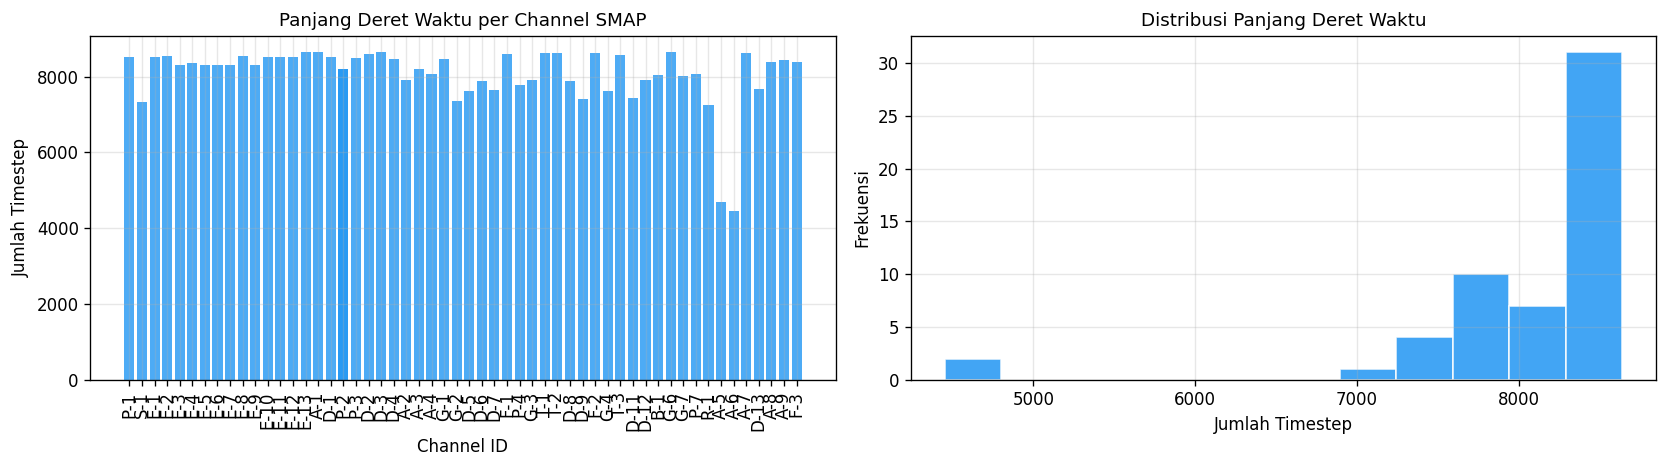

count      55.0
mean     8073.4
std       795.5
min      4453.0
25%      7895.5
50%      8307.0
75%      8515.0
max      8640.0


In [3]:
lengths = smap['num_values'].values
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].bar(smap['chan_id'], lengths, color=COLORS['normal'], alpha=0.8)
axes[0].set_xlabel('Channel ID')
axes[0].set_ylabel('Jumlah Timestep')
axes[0].set_title('Panjang Deret Waktu per Channel SMAP')
axes[0].tick_params(axis='x', rotation=90)

axes[1].hist(lengths, bins=12, color=COLORS['normal'], edgecolor='white', alpha=0.85)
axes[1].set_xlabel('Jumlah Timestep')
axes[1].set_ylabel('Frekuensi')
axes[1].set_title('Distribusi Panjang Deret Waktu')

plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_smap_lengths.png', bbox_inches='tight')
plt.show()
print(pd.Series(lengths).describe().round(1).to_string())


## 3. Distribusi Tipe Anomali

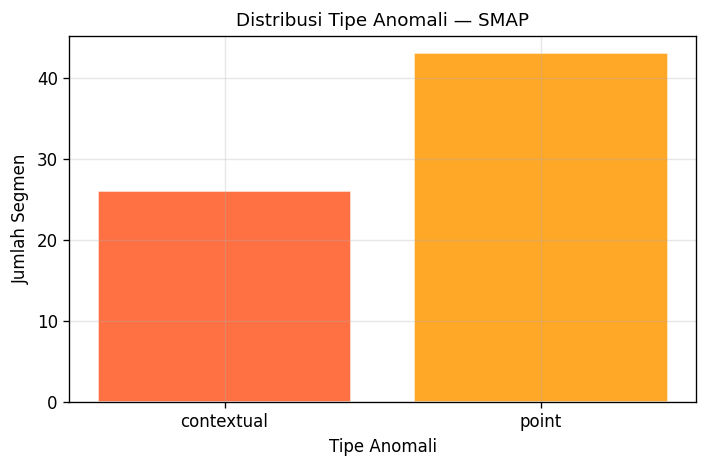

  contextual     : 26 segmen
  point          : 43 segmen


In [4]:
import re
import ast
from collections import Counter

def parse_class(c):
    return re.findall(r'[A-Za-z_][A-Za-z0-9_]*', str(c))

def parse_seqs(s):
    return ast.literal_eval(s)

all_types = []
for _, row in smap.iterrows():
    all_types.extend(parse_class(row['class']))

type_counts = Counter(all_types)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(type_counts.keys(), type_counts.values(),
       color=[COLORS['anomaly'], '#FF9800'], edgecolor='white', alpha=0.85)
ax.set_xlabel('Tipe Anomali')
ax.set_ylabel('Jumlah Segmen')
ax.set_title('Distribusi Tipe Anomali — SMAP')
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_smap_anomaly_types.png', bbox_inches='tight')
plt.show()
for k, v in type_counts.items():
    print(f"  {k:15s}: {v} segmen")


## 4. Visualisasi Sampel Channel

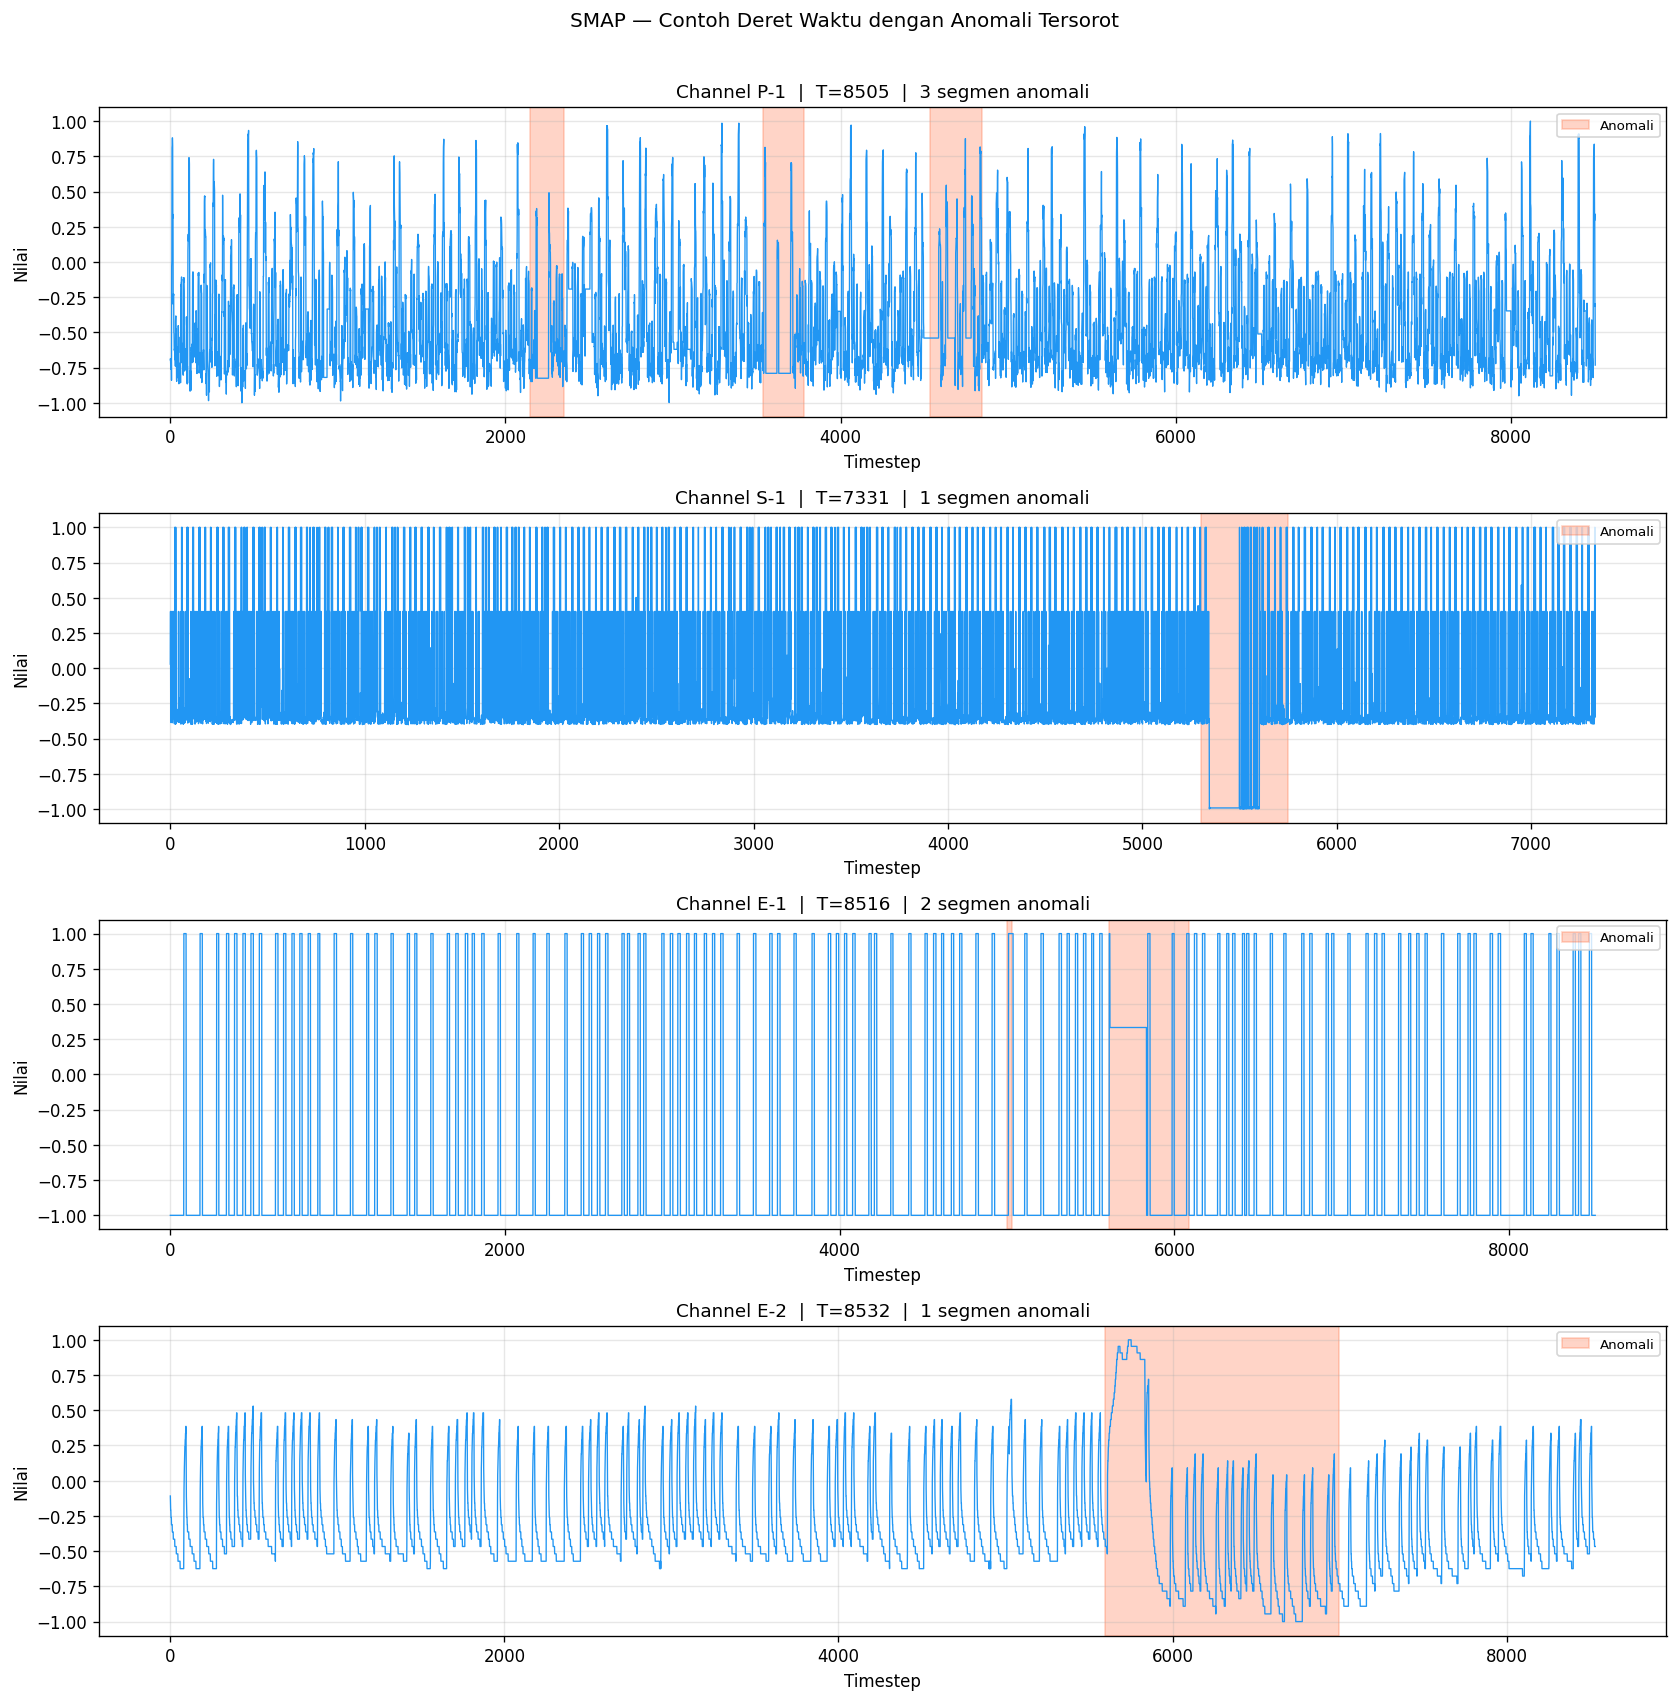

In [5]:
def load_smap(chan_id, split='test'):
    return np.load(DATA_DIR / 'data' / split / f'{chan_id}.npy')

sample_chans = smap['chan_id'].iloc[:4].tolist()
fig, axes = plt.subplots(len(sample_chans), 1, figsize=(14, 3.5 * len(sample_chans)))

for ax, chan_id in zip(axes, sample_chans):
    row = smap[smap['chan_id'] == chan_id].iloc[0]
    data = load_smap(chan_id, 'test')
    T = data.shape[0]
    ax.plot(np.arange(T), data[:, 0], color=COLORS['normal'], linewidth=0.8)
    seqs = parse_seqs(row['anomaly_sequences'])
    for i, (s, e) in enumerate(seqs):
        ax.axvspan(s, e, color=COLORS['anomaly'], alpha=0.25,
                   label='Anomali' if i == 0 else '_')
    ax.set_title(f'Channel {chan_id}  |  T={T}  |  {len(seqs)} segmen anomali')
    ax.set_xlabel('Timestep')
    ax.set_ylabel('Nilai')
    ax.legend(fontsize=8, loc='upper right')

plt.suptitle('SMAP — Contoh Deret Waktu dengan Anomali Tersorot', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_smap_timeseries.png', bbox_inches='tight')
plt.show()


## 5. Rasio Anomali per Channel

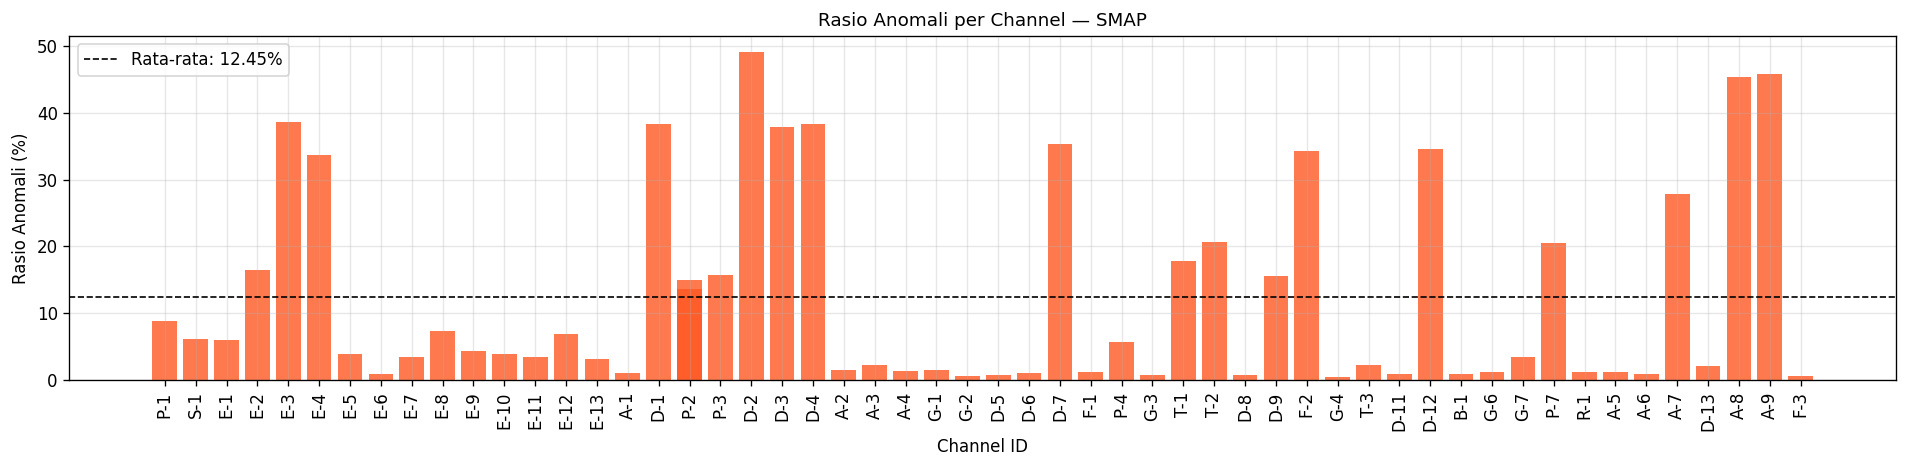

Rata-rata rasio anomali : 12.45%


In [6]:
anomaly_ratios = []
for _, row in smap.iterrows():
    T = row['num_values']
    seqs = parse_seqs(row['anomaly_sequences'])
    n_anom = sum(e - s + 1 for s, e in seqs)
    anomaly_ratios.append(n_anom / T * 100)
smap['anomaly_ratio_%'] = anomaly_ratios

fig, ax = plt.subplots(figsize=(16, 4))
ax.bar(smap['chan_id'], smap['anomaly_ratio_%'], color=COLORS['anomaly'], alpha=0.8)
ax.axhline(np.mean(anomaly_ratios), color='black', linestyle='--', linewidth=1,
           label=f'Rata-rata: {np.mean(anomaly_ratios):.2f}%')
ax.set_xlabel('Channel ID')
ax.set_ylabel('Rasio Anomali (%)')
ax.set_title('Rasio Anomali per Channel — SMAP')
ax.tick_params(axis='x', rotation=90)
ax.legend()
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_smap_anomaly_ratio.png', bbox_inches='tight')
plt.show()
print(f"Rata-rata rasio anomali : {np.mean(anomaly_ratios):.2f}%")


## 6. Perbandingan Statistik Train vs Test (Channel P-1)

Channel P-1:
  Train shape : (2872, 25)
  Test shape  : (8505, 25)


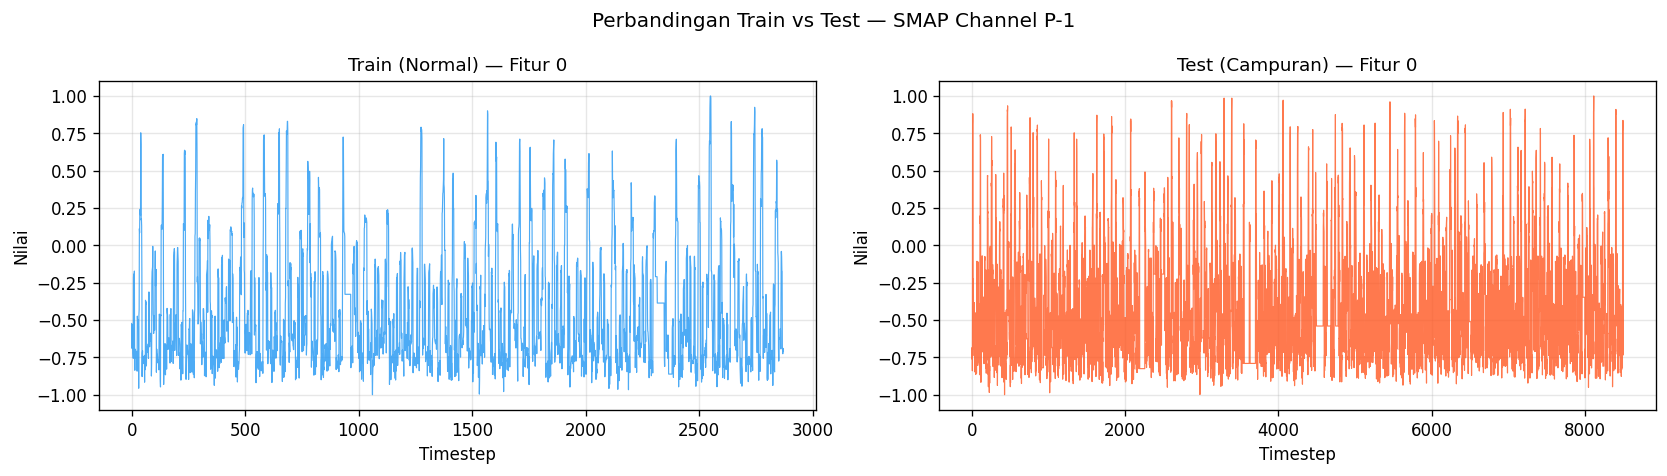

In [7]:
chan = 'P-1'
tr = load_smap(chan, 'train')
te = load_smap(chan, 'test')

print(f"Channel {chan}:")
print(f"  Train shape : {tr.shape}")
print(f"  Test shape  : {te.shape}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for i, (name, data, color) in enumerate([
        ('Train (Normal)', tr, COLORS['normal']),
        ('Test (Campuran)', te, COLORS['anomaly'])]):
    axes[i].plot(data[:, 0], color=color, linewidth=0.7, alpha=0.8)
    axes[i].set_title(f'{name} — Fitur 0')
    axes[i].set_xlabel('Timestep')
    axes[i].set_ylabel('Nilai')
plt.suptitle(f'Perbandingan Train vs Test — SMAP Channel {chan}')
plt.tight_layout()
plt.savefig(BASE / 'results' / 'figures' / 'eda_smap_train_test.png', bbox_inches='tight')
plt.show()


## 7. Ringkasan Dataset SMAP

In [8]:
print("=" * 50)
print("RINGKASAN DATASET SMAP")
print("=" * 50)
total_segs = sum(len(parse_seqs(r)) for r in smap['anomaly_sequences'])
print(f"Jumlah channel          : {len(smap)}")
print(f"Jumlah fitur per sample : {load_smap(smap.iloc[0]['chan_id'], 'test').shape[1]}")
print(f"Rata-rata panjang test  : {smap['num_values'].mean():.0f} timestep")
print(f"Total segmen anomali    : {total_segs}")
print(f"Rata-rata rasio anomali : {np.mean(anomaly_ratios):.2f}%")
print(f"Tipe anomali            : point, contextual")


RINGKASAN DATASET SMAP
Jumlah channel          : 55
Jumlah fitur per sample : 25
Rata-rata panjang test  : 8073 timestep
Total segmen anomali    : 69
Rata-rata rasio anomali : 12.45%
Tipe anomali            : point, contextual
